# 01. Multiple Linear Regression

**Project** · House Price Prediction  
**Problem type** · Regression

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

Ordinary least squares combines several measurements into one continuous estimate. House size, amenities and location can all contribute to the same predicted price. The same approach can estimate monthly operating costs from staffing, usage and rent.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Price starts at 125,000 USD. It gains 155 USD per ft², 12,500 USD per bedroom and 18,500 USD per bathroom, and loses 1,500 USD per year of age and 2,900 USD per km from the centre. Independent Gaussian noise has a standard deviation of 31,000 USD. Prices are floored at 40,000 USD. Bedroom count is related to area, and bathrooms are related to bedrooms.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `area_sqft` | integer | ft² | Interior floor area |
| `bedrooms` | integer | count | Number of bedrooms |
| `bathrooms` | integer | count | Number of bathrooms |
| `house_age_years` | integer | years | Age of the house at sale |
| `city_centre_distance_km` | decimal | km | Distance from the city centre |
| `house_price_usd` | decimal | USD | Observed continuous outcome |

**Independent variables (X)** · `area_sqft`, `bedrooms`, `bathrooms`, `house_age_years`, `city_centre_distance_km`.

**Dependent variable (y)** · `house_price_usd` is the continuous quantity to predict in USD. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "01_house_prices.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 6)


,area_sqft,bedrooms,bathrooms,house_age_years,city_centre_distance_km,house_price_usd
0,2216,3,3,60,15.23,412115.40
1,3537,5,3,58,10.14,623034.29
2,2481,4,2,28,8.57,530056.26
3,3519,4,4,14,10.73,731365.90
4,1336,2,1,40,19.38,315800.86
5,3411,6,5,37,7.60,750389.86
6,1731,2,1,13,15.87,380283.39
7,1624,4,3,58,24.45,274334.79
8,2389,4,3,14,6.63,592240.05
9,3657,6,5,61,2.06,776166.72


area_sqft                    int64
bedrooms                     int64
bathrooms                    int64
house_age_years              int64
city_centre_distance_km    float64
house_price_usd            float64
dtype: object

## 3. Mathematical Understanding

The prediction is $\hat y=b+\sum_{j=1}^{p}w_j x_j$. Here $b$ is the intercept, $p$ the number of predictors, $x_j$ the value of feature $j$, and $w_j$ its coefficient. The fit minimizes $\sum_{i=1}^n(y_i-\hat y_i)^2$, where $i$ indexes the $n$ training homes, $y_i$ is the observed sale price and $\hat y_i$ is its estimate.

Suppose a two-feature model has $b=50{,}000$, an area coefficient of $150$ USD/ft² and a bathroom coefficient of $20{,}000$ USD. A 1,000 ft² home with two bathrooms gives $50{,}000+150(1000)+20{,}000(2)=240{,}000$ USD. At fixed area, a third bathroom changes this estimate by 20,000 USD.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares)

## 4. Working Principle

Think of an itemized quote. Start at an intercept, add or subtract each feature’s contribution, and adjust the weights together to minimize the squared errors. The fitted relationships describe how predictions change while the other inputs are held fixed.

| Contribution | Value |
| --- | --- |
| Intercept | 50,000 USD |
| Floor area | 150 × 1,000 = 150,000 USD |
| Bathrooms | 20,000 × 2 = 40,000 USD |
| Estimated price | 240,000 USD |

**Workflow diagram**

`Raw input` → `Standardized numeric values and any category indicators` → `Fits an additive conditional mean by minimizing squared errors` → `Estimate in USD`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows the range and shape of the outcome. Feature plots show variation. Pearson correlation measures linear association. Watch for nonlinear trends even if a linear association is present. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "house_price_usd"
FEATURES = ["area_sqft","bedrooms","bathrooms","house_age_years","city_centre_distance_km"]
NUMERIC = ["area_sqft","bedrooms","bathrooms","house_age_years","city_centre_distance_km"]
CATEGORICAL = []
SEED = 42

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area_sqft                1500 non-null   int64  
 1   bedrooms                 1500 non-null   int64  
 2   bathrooms                1500 non-null   int64  
 3   house_age_years          1500 non-null   int64  
 4   city_centre_distance_km  1470 non-null   float64
 5   house_price_usd          1500 non-null   float64
dtypes: float64(2), int64(4)
memory usage: 70.4 KB


,area_sqft,bedrooms,bathrooms,house_age_years,city_centre_distance_km,house_price_usd
0,2216,3,3,60,15.23,412115.40
1,3537,5,3,58,10.14,623034.29
2,2481,4,2,28,8.57,530056.26
3,3519,4,4,14,10.73,731365.90
4,1336,2,1,40,19.38,315800.86


,area_sqft,bedrooms,bathrooms,house_age_years,city_centre_distance_km,house_price_usd
1495,3134,5,4,40,3.14,687665.09
1496,3020,4,2,56,10.52,566957.61
1497,1513,4,4,42,10.77,423950.63
1498,928,1,1,14,9.81,220858.99
1499,2248,3,3,55,13.53,482736.64


,count,mean,std,min,25%,50%,75%,max
area_sqft,1500.0,2228.697333,904.871550,651.00,1429.7500,2250.500,3021.000,3799.00
bedrooms,1500.0,3.505333,1.351736,1.00,2.0000,4.000,5.000,6.00
bathrooms,1500.0,2.626667,1.359603,1.00,1.0000,3.000,4.000,5.00
house_age_years,1500.0,32.008667,18.583438,0.00,16.0000,32.000,48.000,64.00
city_centre_distance_km,1470.0,16.279701,8.903467,1.03,8.8375,15.835,24.010,32.00
house_price_usd,1500.0,467338.519813,180820.104471,57682.93,314096.1175,463358.550,619622.125,893641.19


,Missing,Missing %
area_sqft,0,0.0
bedrooms,0,0.0
bathrooms,0,0.0
house_age_years,0,0.0
city_centre_distance_km,30,2.0
house_price_usd,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

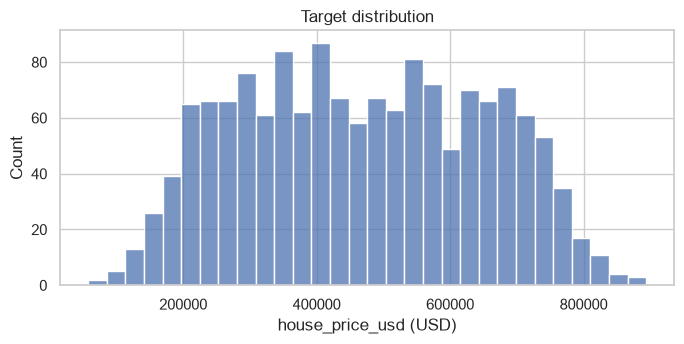

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x=TARGET, bins=30, ax=ax)
ax.set_xlabel("house_price_usd (USD)")
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

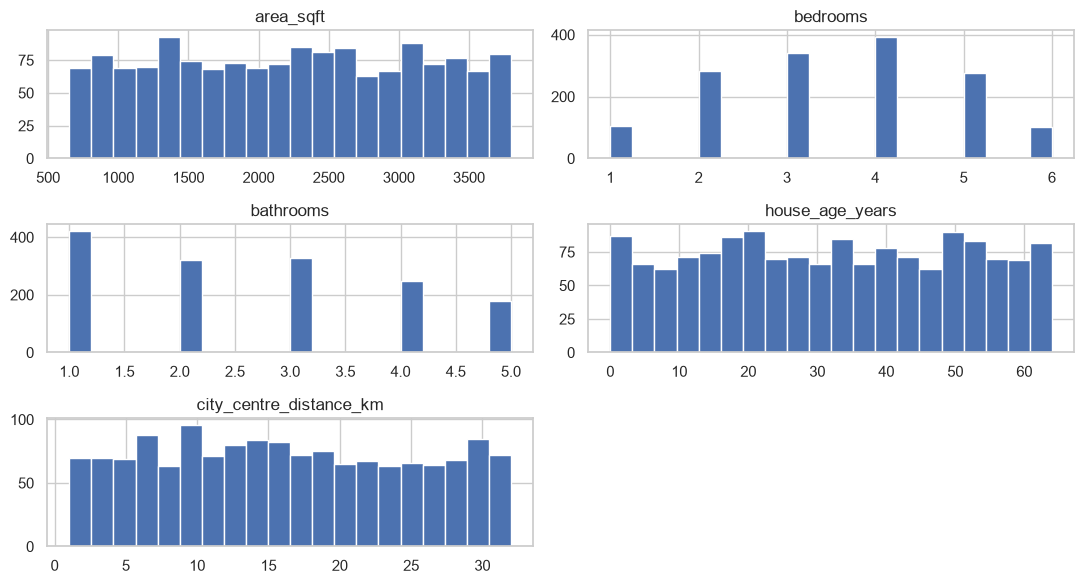

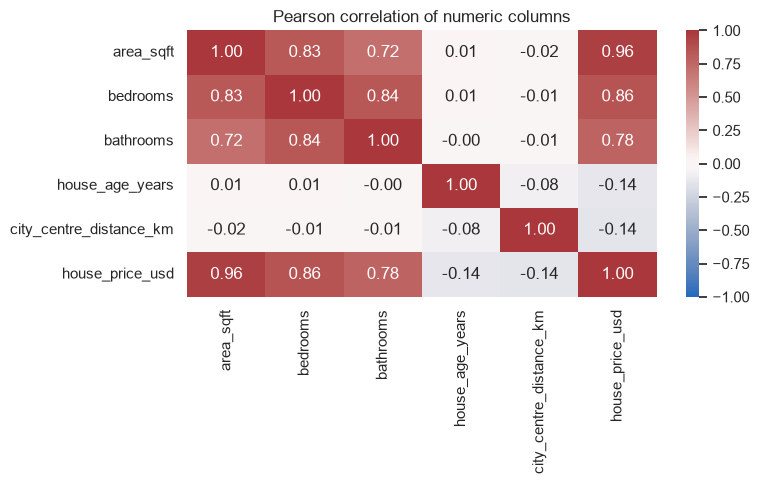

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC + [TARGET]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. A seeded random split suits these independently generated rows. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. StandardScaler uses training means and standard deviations to make numeric magnitudes comparable. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
y = df[TARGET]

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fill blank numbers, then put numeric columns on comparable scales.
numeric_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`LinearRegression()` fits an intercept by default and has no shrinkage strength. `Ridge` adds an L2 penalty proportional to `alpha`, which helps when predictors are correlated. Standardization puts the penalty on comparable scales. The coefficient plot converts the fitted OLS slopes back to original units.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.linear_model import LinearRegression, Ridge

estimator = LinearRegression()
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['area_sqft','bedrooms','bathrooms','house_age_years', 'city_centre_distance_km']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and 

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print(f"Example prediction: {predictions[0]:,.2f} USD")

,area_sqft,bedrooms,bathrooms,house_age_years,city_centre_distance_km
1116,3516,6,5,37,22.57


Example prediction: 716,559.90 USD


## 8. Model Evaluation

Let $y_i$ be the actual test value for row $i$, $\hat y_i$ its prediction, $e_i=y_i-\hat y_i$ its residual, $n$ the number of test rows and $\bar y$ the test target mean.

| Metric | Formula | Interpretation |
| --- | --- | --- |
| Mean absolute error | $\mathrm{MAE}=n^{-1}\sum_i\lvert e_i\rvert$ | Mean absolute miss in the target unit. Lower is better. |
| Mean squared error | $\mathrm{MSE}=n^{-1}\sum_i e_i^2$ | Mean squared miss in squared units. It puts more weight on large errors. Lower is better. |
| Root mean squared error | $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ | Error on the target scale that emphasizes large misses. Lower is better. |
| Coefficient of determination | $R^2=1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Higher is better. One is a perfect fit, zero matches the squared error of the test mean, and negative means more error than that reference. |

The baseline predicts the **training** target mean, so its test R² may be slightly negative. Compare MAE and RMSE to it in the table below.

**Target unit** · USD.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

initial_metrics = {
    "MAE": mean_absolute_error(y_test, predictions),
    "MSE": mean_squared_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R²": r2_score(y_test, predictions),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

MAE     2.485366e+04
MSE     9.967998e+08
RMSE    3.157214e+04
R²      9.680000e-01
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline predicts the mean training target for every row.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_metrics = {
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "MSE": mean_squared_error(y_test, baseline_predictions),
    "RMSE": root_mean_squared_error(y_test, baseline_predictions),
    "R²": r2_score(y_test, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,MAE,MSE,RMSE,R²
Baseline,150075.555,3.146210e+10,177375.583,-0.002
Model,24853.662,9.967998e+08,31572.136,0.968


## 9. Visualizations

Compare estimated and measured outcomes against the 45-degree line. A point above that line is an overestimate. In the residual panel, points above zero are underestimates. A systematic curve suggests missing structure, and widening scatter suggests changing error spread.

A coefficient gives the predicted USD change for one original unit of a feature while holding the other inputs constant. The predictors use different units, so bar lengths cannot rank practical importance.

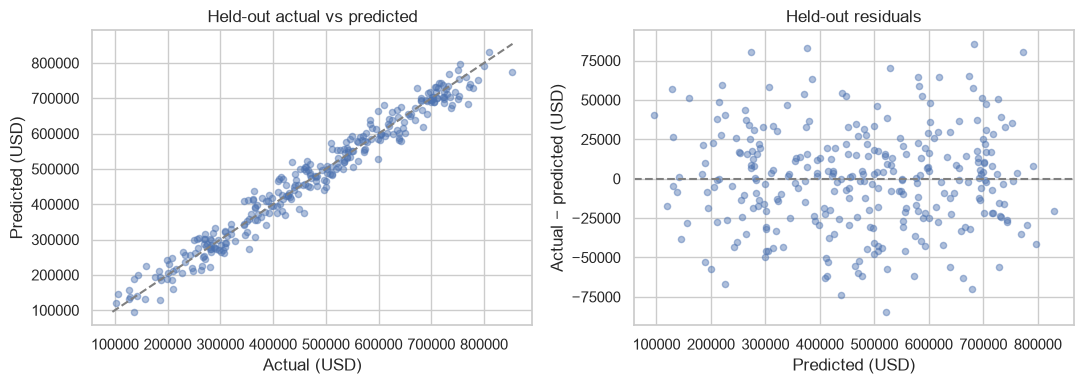

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, s=20, alpha=0.45)
axes[0].plot(limits, limits, color="grey", linestyle="--")
axes[0].set(xlabel="Actual (USD)", ylabel="Predicted (USD)", title="Held-out actual vs predicted")
axes[1].scatter(predictions, y_test - predictions, s=20, alpha=0.45)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Predicted (USD)", ylabel="Actual − predicted (USD)", title="Held-out residuals")
fig.tight_layout()
plt.show()

### A closer look at this model

,USD per original feature unit
area_sqft,155.52
bedrooms,10774.84
bathrooms,20070.12
house_age_years,-1512.20
city_centre_distance_km,-2854.95


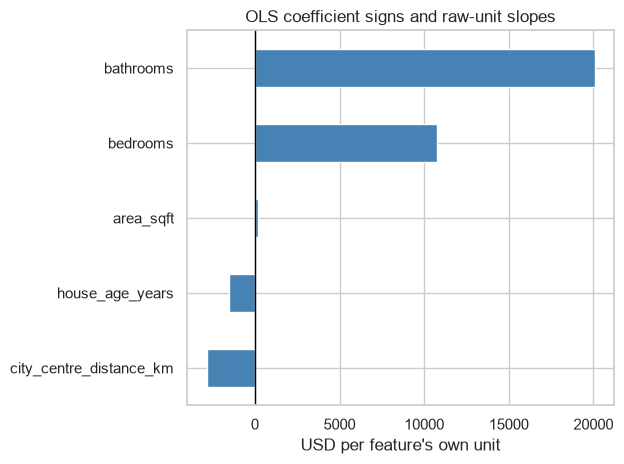

In [15]:
scaler = model.named_steps["preprocess"].named_transformers_["numeric"].named_steps["scale"]
slopes = model.named_steps["model"].coef_ / scaler.scale_
slope_table = pd.Series(slopes, index=FEATURES, name="USD per original feature unit")
display(slope_table.to_frame().round(2))
ax = slope_table.sort_values().plot.barh(color="steelblue")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("OLS coefficient signs and raw-unit slopes")
ax.set_xlabel("USD per feature's own unit")
plt.tight_layout()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by lowest RMSE. The scorer negates RMSE so that the best score ranks first. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`LinearRegression()` fits an intercept by default and has no shrinkage strength. `Ridge` adds an L2 penalty proportional to `alpha`, which helps when predictors are correlated. Standardization puts the penalty on comparable scales. The coefficient plot converts the fitted OLS slopes back to original units.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [16]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = [{"model": [LinearRegression()]}, {"model": [Ridge()], "model__alpha": [0.1, 1, 10, 50]}]
validation = KFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="neg_root_mean_squared_error", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [17]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean fold RMSE"] = -results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean fold RMSE", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model': Ridge(), 'model__alpha': 0.1}


,rank_test_score,Mean fold RMSE,std_test_score,params
1,1,30851.032,1144.481,"{'model': Ridge(), 'model__alpha': 0.1}"
0,2,30851.089,1144.389,{'model': LinearRegression()}
2,3,30851.815,1145.576,"{'model': Ridge(), 'model__alpha': 1}"
3,4,30971.732,1178.385,"{'model': Ridge(), 'model__alpha': 10}"
4,5,32881.335,1535.650,"{'model': Ridge(), 'model__alpha': 50}"


### Compare the models on the test set

In [18]:
tuned_predictions = tuned_model.predict(X_test)

tuned_metrics = {
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "RMSE": root_mean_squared_error(y_test, tuned_predictions),
    "R²": r2_score(y_test, tuned_predictions),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,MAE,MSE,RMSE,R²
Baseline,150075.555,3.146210e+10,177375.583,-0.002
First model,24853.662,9.967998e+08,31572.136,0.968
Tuned model,24852.995,9.967210e+08,31570.889,0.968


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. Read the estimates in USD and compare the scenarios to see how the fitted model responds.

### Enter three new examples

In [19]:
examples = pd.DataFrame([
    [1250, 2, 1, 12, 5],
    [2450, 4, 3, 28, 18],
    [3550, 5, 4, 3, 8],
], columns=FEATURES)
display(examples)

,area_sqft,bedrooms,bathrooms,house_age_years,city_centre_distance_km
0,1250,2,1,12,5
1,2450,4,3,28,18
2,3550,5,4,3,8


### Make predictions

In [20]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Compact home near the centre","Older family home farther out","Large, newer home"]
example_output["Predicted house_price_usd (USD)"] = sample_predictions.round(2)
display(example_output)

,area_sqft,bedrooms,bathrooms,house_age_years,city_centre_distance_km,Scenario,Predicted house_price_usd (USD)
0,1250,2,1,12,5,Compact home near the centre,328731.40
1,2450,4,3,28,18,Older family home farther out,515739.69
2,3550,5,4,3,8,"Large, newer home",783988.83


## 12. Limitations and Advantages

OLS is fast and the slopes are easy to interpret in original units. Its conditional mean is additive and linear in the chosen features. Correlated room counts can make individual slopes unstable, and squared loss is sensitive to outliers. Curvature in residuals suggests underfitting. Adding many weak features can overfit, so compare against a regularized fit. Use it as a structured baseline when an additive trend is plausible. Prefer another specification when interactions or strong curvature dominate.

## 13. Interview Preparation

### A. 30-second explanation

> I used ordinary least squares to predict a synthetic home’s price from floor area, rooms, age and distance. Each slope measures the prediction change for one feature at fixed values of the others. I compared the estimates with a simple price baseline using held-out dollar errors and checked whether Ridge helped on training folds.

### B. 90-second technical explanation

> I used ordinary least squares to predict a synthetic home’s price from floor area, rooms, age and distance. Each slope measures the prediction change for one feature at fixed values of the others. I compared the estimates with a simple price baseline using held-out dollar errors and checked whether Ridge helped on training folds. My target was house price usd, and the inputs were area sqft, bedrooms, bathrooms, house age years, city centre distance km. Think of an itemized quote. Start at an intercept, add or subtract each feature’s contribution, and adjust the weights together to minimize the squared errors. The fitted relationships describe how predictions change while the other inputs are held fixed. I held out 20% of the rows and fitted preprocessing within each training fold. I measured MAE in USD and RMSE to see how much larger errors mattered. I compared the model with a training-mean predictor and inspected residuals. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What makes it multiple?** There is one target and more than one input.
2. **What do the fitted coefficients represent?** A change in conditional prediction per unit of a feature at fixed values of the other inputs.
3. **What does the intercept represent?** The prediction when transformed inputs equal zero. Under centering this is the prediction at the training feature means.
4. **Why use squared loss?** It yields a tractable least-squares problem and penalizes large residuals heavily.
5. **What is multicollinearity?** Several predictors carry overlapping information, so their individual coefficients can be unstable.
6. **Do OLS predictions require normally distributed features?** No. Classical inference relies on additional assumptions about the errors.
7. **What is heteroscedasticity?** The variance of residuals changes with feature values or fitted values.
8. **Why compare Ridge?** Shrinkage can reduce variance when predictors are noisy or correlated.
9. **Can a coefficient establish causality?** No. The observational fit describes conditional association without a causal identification design.
10. **How do you interpret negative test R²?** The squared error exceeds that of a predictor using the test target mean as a reference.

### D. Five scenario questions

1. **Area and bedrooms have a high correlation. What would you inspect?** Compare coefficient stability across folds and try Ridge before drawing conclusions from individual slopes.
2. **Dollar errors grow with price. What can you try?** Inspect a residual-vs-fitted plot and validate a log-target model using dollar-unit errors.
3. **Residuals curve with age. What could improve the model?** Add a prespecified nonlinear age feature and validate on training folds.
4. **An input is a 15,000 ft² mansion. How would you interpret the estimate?** Flag extrapolation and obtain representative observations before using that range.
5. **You want to know if adding a bathroom causes a given price increase. What is missing?** An identification design that addresses confounding and selection.

### E. Three common mistakes

- Reading a standardized slope as USD per original unit. Divide by the training scale first.
- Assuming bedrooms and bathrooms are independent. Inspect their correlation.
- Optimizing feature choices on the test set. Keep those choices inside cross-validation.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [21]:
from IPython.display import Markdown

summary = (
    "I built a supervised regression project for house price prediction using Multiple Linear Regression. I generated 1,500 synthetic observations and used area sqft, bedrooms, bathrooms, house age years, city centre distance km to predict house price usd. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model achieved MAE {tuned_metrics['MAE']:,.2f} USD, "
    f"compared with {baseline_metrics['MAE']:,.2f} USD for the training-mean baseline. "
    f"Its RMSE was {tuned_metrics['RMSE']:,.2f} USD. "
    "I converted standardized coefficients back to their original feature units and checked residuals for evidence of curvature. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised regression project for house price prediction using Multiple Linear Regression. I generated 1,500 synthetic observations and used area sqft, bedrooms, bathrooms, house age years, city centre distance km to predict house price usd. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model achieved MAE 24,852.99 USD, compared with 150,075.55 USD for the training-mean baseline. Its RMSE was 31,570.89 USD. I converted standardized coefficients back to their original feature units and checked residuals for evidence of curvature. These results apply to the synthetic data and should be validated on representative observations before practical use.